# EDA · Hotel Valle de Cocora
### Habitaciones vacías por reservas que nunca llegan

**Proyecto tercer corte · Programación Aplicada · Universidad de La Sabana** · versión 2 (corregida tras auditoría)

Este notebook es el **Análisis Exploratorio de Datos (EDA)** del caso. Su propósito, según el enunciado, es mostrar comprensión de los datos y **justificar las 3 preguntas de enfoque** del proyecto. Cada pregunta viene con sus KPIs y OKR (retroalimentación del profesor); aquí buscamos la **evidencia en los datos** que sostiene cada una.

| # | Pregunta de enfoque | Decisión que habilita |
|---|---|---|
| 1 | ¿Es posible anticipar cuántas reservas se cancelarán, para aceptar reservas adicionales y evitar habitaciones vacías? | Cuántas reservas adicionales aceptar por encima de la capacidad del hotel para compensar las cancelaciones esperadas (sobreventa controlada) |
| 2 | ¿Qué clientes tienen más probabilidad de cancelar, y cuánta plata se ahorra el hotel si solo a ellos les pide un pago por adelantado? | A quién pedirle depósito |
| 3 | En Booking y Airbnb, ¿cuánto baja la cancelación si las reservas Flexibles pasan a Moderada o pagan depósito? | Cómo ajustar las políticas por canal |

**Ruta del notebook:** 1) calidad de datos → 2) limpieza y decisiones → 3) panorama general → 4) evidencia para P1 → 5) evidencia para P2 → 6) evidencia para P3 → 7) conclusiones y limitaciones.

> **Dos bases, cada una para lo que sirve.** Las cifras *históricas* (tasas por canal, depósito, política) usan las **100.000 reservas únicas completas**, que es la base con la que el PDF del profesor calcula sus KPIs. Las *series de tiempo y el modelo* usan una **ventana temporal confiable** (1-may-2023 → 18-jun-2025), porque el historial tiene una rampa de arranque y un corte al final (se explica en la sección 2.3). La sección 3.3 muestra que la elección cambia las tasas en menos de 1 punto porcentual.
>
> Los KPIs del PDF (74,1 %, $1.149 M, 21,6 %…) son **metas del modelo** de la fase técnica. Aquí no los replicamos: mostramos que los datos tienen la señal necesaria para perseguirlos.

## 1. Configuración y carga de datos

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, ROJO, GRIS, VERDE = "#2563eb", "#dc2626", "#9ca3af", "#16a34a"
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 40

SEMILLA = 42                                   # fija los resultados del modelo para que sean reproducibles
INI_VENTANA = pd.Timestamp("2023-05-01")       # antes de esta fecha el historial está incompleto (rampa de arranque)
FIN_VENTANA = pd.Timestamp("2025-06-18")       # última fecha de reserva registrada: después no hay datos completos
HABITACIONES = 38                              # capacidad real del hotel según el caso

def pct(ax, eje="y"):
    f = mtick.PercentFormatter(1.0, decimals=0)
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(f)

def millones(x):
    return f"${x/1e6:,.0f} M"

def ic95(p, n):
    return 1.96 * np.sqrt(p * (1 - p) / n)     # semiancho del intervalo de confianza al 95 % de una proporción

raw = pd.read_csv("../../datos/hotel_reservas.csv", parse_dates=["fecha_reserva", "fecha_llegada"])
print(f"Registros: {raw.shape[0]:,} | Variables: {raw.shape[1]}")
raw.head()

Registros: 100,300 | Variables: 20


,id_reserva,fecha_reserva,anticipacion_dias,fecha_llegada,mes_llegada,noches,adultos,ninos,tipo_habitacion,canal,pais_origen,tarifa_noche,politica_cancelacion,deposito_pagado,huesped_recurrente,solicitudes_especiales,cancelaciones_previas,incluye_desayuno,cancelada,ingreso_total
0,32834,2024-05-04,68,2024-07-11,7,3,4,0,Doble,Agencia,Colombia,"295,000.00",No reembolsable,1,0,1,0,0,0,"885,000.00"
1,93669,2024-06-02,29,2024-07-01,7,2,3,0,Doble,Directo web,Colombia,"240,000.00",Flexible,1,0,0,0,1,0,"480,000.00"
2,30892,2023-02-07,70,2023-04-18,4,2,2,1,Familiar,Directo web,Otros,"317,000.00",Moderada,0,0,0,0,0,0,"634,000.00"
3,79018,2024-01-03,38,2024-02-10,2,4,2,0,Familiar,Directo web,Argentina,"267,000.00",Flexible,0,0,2,0,1,0,"1,068,000.00"
4,94632,2023-07-14,14,2023-07-28,7,5,3,1,Doble,Agencia,México,"261,000.00",Flexible,0,1,1,0,0,0,"1,305,000.00"


**Diccionario resumido.** `cancelada` es la variable objetivo (1 = se canceló). `ingreso_total` es 0 cuando la reserva se cancela, por lo que **es una consecuencia de la cancelación y no puede usarse como predictor** (fuga de información). Para medir lo que el hotel pierde construiremos `ingreso_perdido = tarifa_noche × noches` cuando `cancelada = 1`.

## 2. Calidad de los datos

### 2.1 Estructura, nulos y duplicados

In [2]:
resumen = pd.DataFrame({
    "tipo": raw.dtypes.astype(str),
    "nulos": raw.isna().sum(),
    "% nulos": (raw.isna().mean() * 100).round(2),
    "valores únicos": raw.nunique(),
})
display(resumen)

n_dup = raw.duplicated().sum()
n_id_dup = raw["id_reserva"].duplicated().sum()
print(f"Filas completamente duplicadas: {n_dup}  |  id_reserva repetidos: {n_id_dup}")

,tipo,nulos,% nulos,valores únicos
id_reserva,int64,0,0.00,100000
fecha_reserva,datetime64[us],0,0.00,900
anticipacion_dias,int64,0,0.00,333
fecha_llegada,datetime64[us],0,0.00,1130
mes_llegada,int64,0,0.00,12
noches,int64,0,0.00,13
adultos,int64,0,0.00,5
ninos,int64,0,0.00,4
tipo_habitacion,str,0,0.00,4
canal,str,4019,4.01,5


Filas completamente duplicadas: 300  |  id_reserva repetidos: 300


**Lectura.** Faltan datos solo en `canal` y `pais_origen` (4,0 % y 3,9 %), coherente con lo que advierte el caso (cambio de proveedor). Además hay **300 filas duplicadas exactas**: el archivo trae 100.300 registros pero solo 100.000 reservas únicas.

### 2.2 Coherencia interna

In [3]:
chequeos = {
    "anticipacion_dias = llegada − reserva": (raw["fecha_llegada"] - raw["fecha_reserva"]).dt.days.eq(raw["anticipacion_dias"]).mean(),
    "mes_llegada coincide con fecha_llegada": raw["fecha_llegada"].dt.month.eq(raw["mes_llegada"]).mean(),
    "ingreso = tarifa × noches (no canceladas)": np.isclose(raw.loc[raw.cancelada == 0, "ingreso_total"],
                                                          (raw.tarifa_noche * raw.noches)[raw.cancelada == 0]).mean(),
    "ingreso = 0 en canceladas": raw.loc[raw.cancelada == 1, "ingreso_total"].eq(0).mean(),
}
display(pd.Series(chequeos, name="% de filas coherentes").map("{:.1%}".format).to_frame())

display(raw[["anticipacion_dias", "noches", "adultos", "ninos", "tarifa_noche", "solicitudes_especiales", "cancelaciones_previas"]].describe().T)
print("Rango de fechas de reserva :", raw.fecha_reserva.min().date(), "→", raw.fecha_reserva.max().date())
print("Rango de fechas de llegada :", raw.fecha_llegada.min().date(), "→", raw.fecha_llegada.max().date())

# Valores atípicos: proporción fuera de 1,5 × rango intercuartílico
for c in ["tarifa_noche", "noches", "anticipacion_dias", "adultos"]:
    q1, q3 = raw[c].quantile([.25, .75]); i = q3 - q1
    print(f"{c:18s} fuera de 1,5×IQR: {((raw[c] > q3 + 1.5*i) | (raw[c] < q1 - 1.5*i)).mean():.1%}")

,% de filas coherentes
anticipacion_dias = llegada − reserva,100.0%
mes_llegada coincide con fecha_llegada,100.0%
ingreso = tarifa × noches (no canceladas),100.0%
ingreso = 0 en canceladas,100.0%


,count,mean,std,min,25%,50%,75%,max
anticipacion_dias,"100,300.00",55.79,44.01,0.00,24.00,45.00,76.00,365.00
noches,"100,300.00",3.40,1.55,1.00,2.00,3.00,4.00,15.00
adultos,"100,300.00",2.19,1.07,1.00,1.00,2.00,3.00,5.00
ninos,"100,300.00",0.40,0.63,0.00,0.00,0.00,1.00,3.00
tarifa_noche,"100,300.00","239,968.05","77,399.44","80,000.00","187,000.00","234,000.00","286,000.00","683,000.00"
solicitudes_especiales,"100,300.00",0.70,0.83,0.00,0.00,1.00,1.00,5.00
cancelaciones_previas,"100,300.00",0.18,0.43,0.00,0.00,0.00,0.00,4.00


Rango de fechas de reserva : 2023-01-01 → 2025-06-18
Rango de fechas de llegada : 2023-01-04 → 2026-04-27
tarifa_noche       fuera de 1,5×IQR: 1.5%
noches             fuera de 1,5×IQR: 1.2%
anticipacion_dias  fuera de 1,5×IQR: 3.6%
adultos            fuera de 1,5×IQR: 0.0%


**Lectura.** Las relaciones aritméticas son 100 % consistentes (fechas, ingreso y mes). Los rangos son plausibles. Los valores atípicos son pocos (tarifa 1,5 %, noches 1,2 %, anticipación 3,6 % de las filas) y **corresponden a reservas válidas** (suites caras, estancias largas, reservas con casi un año de antelación), por eso **se conservan**. Hallazgo relevante: **hay llegadas posteriores a junio de 2025 aunque las reservas solo se registran hasta el 18 de junio de 2025**. Se examina a continuación.

### 2.3 Cobertura temporal: qué periodo es confiable

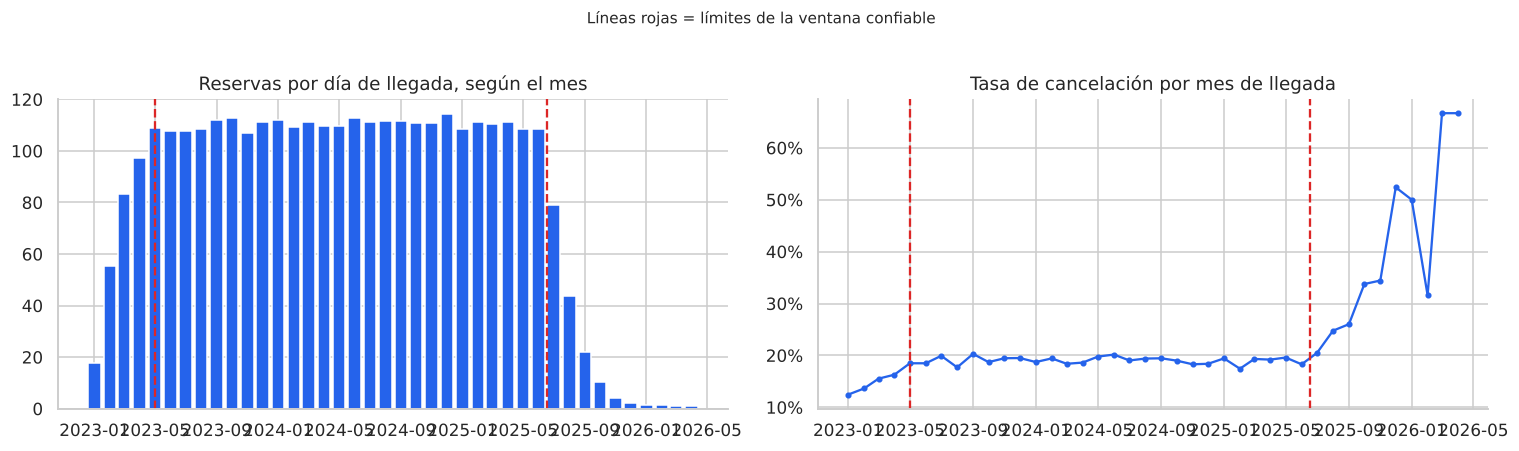

Rampa (llegadas antes de may-2023): 7,531 reservas (7.5%) · cancelación 15.2% · anticipación media 34 días
Cola (llegadas después del 18-jun-2025): 6,301 reservas (6.3%) · cancelación 22.9% · anticipación media 91 días
Resto (ventana):                         cancelación 19.0%


In [4]:
unicas = raw.drop_duplicates()
mensual = (unicas.assign(mes=lambda d: d.fecha_llegada.dt.to_period("M").dt.to_timestamp())
               .groupby("mes")
               .agg(reservas=("cancelada", "size"), dias=("fecha_llegada", "nunique"), tasa_cancel=("cancelada", "mean"))
               .assign(reservas_por_dia=lambda d: d.reservas / d.dias)
               .reset_index())

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(mensual.mes, mensual.reservas_por_dia, width=25, color=AZUL)
for f in (INI_VENTANA, FIN_VENTANA): ax[0].axvline(f, color=ROJO, ls="--")
ax[0].set_title("Reservas por día de llegada, según el mes")
ax[1].plot(mensual.mes, mensual.tasa_cancel, color=AZUL, marker="o", ms=3)
for f in (INI_VENTANA, FIN_VENTANA): ax[1].axvline(f, color=ROJO, ls="--")
ax[1].set_title("Tasa de cancelación por mes de llegada"); pct(ax[1])
plt.suptitle("Líneas rojas = límites de la ventana confiable", y=1.02, fontsize=10)
plt.tight_layout(); plt.show()

rampa = unicas[unicas.fecha_llegada < INI_VENTANA]
cola = unicas[unicas.fecha_llegada > FIN_VENTANA]
for nombre, d in [("Rampa (llegadas antes de may-2023)", rampa), ("Cola (llegadas después del 18-jun-2025)", cola)]:
    print(f"{nombre}: {len(d):,} reservas ({len(d)/len(unicas):.1%}) · cancelación {d.cancelada.mean():.1%} · anticipación media {d.anticipacion_dias.mean():.0f} días")
print(f"Resto (ventana):                         cancelación {unicas[unicas.fecha_llegada.between(INI_VENTANA, FIN_VENTANA)].cancelada.mean():.1%}")

**Lectura.** Dos efectos de borde que no son comportamiento real, sino **límites del registro**:
- **Rampa de arranque (ene–abr 2023):** el historial empieza el 1-ene-2023, así que las llegadas tempranas solo incluyen las reservas hechas con poca antelación (de 18 reservas por día en enero a ≈ 111 desde mayo). Como las reservas hechas con mucha antelación cancelan más, la tasa de esos meses es artificialmente baja (14,6 % en el primer trimestre).
- **Cola (después del 18-jun-2025):** la última reserva registrada es del 18-jun-2025; para llegadas posteriores solo existen reservas muy anticipadas (anticipación media 91 días) y la tasa sube a 22,9 %. Es un efecto de corte.

**Decisión:** para series de tiempo y modelos se usa la **ventana 1-may-2023 → 18-jun-2025**. Coincide con el año de prueba del PDF: 1-jul-2024 → 18-jun-2025 son exactamente **353 noches**, las mismas que cita el KPI de la pregunta 1.

## 3. Limpieza y preparación

### 3.1 Base de trabajo

In [5]:
df = raw.drop_duplicates().copy()            # base completa deduplicada (cifras históricas)

# Faltantes en variables categóricas: se conservan como categoría propia (no se imputan ni se eliminan)
df["canal"] = df["canal"].fillna("No registrado")
df["pais_origen"] = df["pais_origen"].fillna("No registrado")

# Variables derivadas
df["ingreso_potencial"] = df["tarifa_noche"] * df["noches"]
df["ingreso_perdido"] = df["ingreso_potencial"] * df["cancelada"]
df["huespedes"] = df["adultos"] + df["ninos"]
df["anio_llegada"] = df["fecha_llegada"].dt.year
df["dia_semana"] = df["fecha_llegada"].dt.dayofweek
df["temporada_alta"] = df["mes_llegada"].isin([6, 7, 12, 1]).astype(int)
df["rango_anticipacion"] = pd.cut(df["anticipacion_dias"], [-1, 7, 30, 60, 90, 180, 366],
                                  labels=["0-7", "8-30", "31-60", "61-90", "91-180", "181-365"])
df["quintil_tarifa"] = pd.qcut(df["tarifa_noche"], 5, labels=["Q1 (baja)", "Q2", "Q3", "Q4", "Q5 (alta)"])

# Ventana temporal confiable (series de tiempo y modelo)
df["en_ventana"] = df["fecha_llegada"].between(INI_VENTANA, FIN_VENTANA)
dv = df[df["en_ventana"]].copy()

print(f"Filas originales:                   {len(raw):,}")
print(f"− duplicados exactos:                {len(raw) - len(df):,}")
print(f"= Base completa (df):               {len(df):,} reservas  → cifras históricas")
print(f"− fuera de la ventana temporal:      {len(df) - len(dv):,}")
print(f"= Ventana confiable (dv):           {len(dv):,} reservas  → series de tiempo y modelo")

Filas originales:                   100,300
− duplicados exactos:                300
= Base completa (df):               100,000 reservas  → cifras históricas
− fuera de la ventana temporal:      13,832
= Ventana confiable (dv):           86,168 reservas  → series de tiempo y modelo


### 3.2 Decisiones de limpieza y por qué se tomaron

| Problema | Decisión | Por qué |
|---|---|---|
| 300 duplicados exactos | **Eliminados** | Repiten el mismo `id_reserva` y todos los campos: es la misma reserva registrada dos veces. Dejarlos contaría doble la cancelación y el ingreso. |
| Nulos en `canal` y `pais_origen` | **Categoría «No registrado»** | No hay forma de saber el valor real; imputar con el más frecuente inventaría datos y eliminar las filas perdería ≈ 4 % de las reservas. Su tasa de cancelación (19,4 %) es casi igual al promedio: no distorsionan. |
| Rampa de arranque (llegadas < may-2023) | **Se conservan en el análisis histórico, se excluyen de series y modelo** | Son datos válidos para describir tasas, pero incompletos para series de tiempo: faltan las reservas anteriores a enero de 2023. |
| Cola (llegadas > 18-jun-2025) | **Ídem** | Solo contienen reservas muy anticipadas, por lo que su tasa de cancelación está sesgada al alza. |
| Valores atípicos | **Se conservan** | Son reservas válidas y de bajo peso (1 a 4 % de las filas). |
| `ingreso_total` | **No se usa como predictor** | Vale 0 si se cancela: es una consecuencia de la cancelación. |

### 3.3 Sensibilidad: ¿importa la base que se use?

In [6]:
def resumen_base(d):
    return pd.Series({
        "Reservas": len(d),
        "Tasa de cancelación global": d.cancelada.mean(),
        "Sin pago anticipado": d.loc[d.deposito_pagado == 0, "cancelada"].mean(),
        "Con pago anticipado": d.loc[d.deposito_pagado == 1, "cancelada"].mean(),
        "Booking": d.loc[d.canal == "Booking", "cancelada"].mean(),
        "Airbnb": d.loc[d.canal == "Airbnb", "cancelada"].mean(),
        "Booking: % del ingreso perdido": d.loc[d.canal == "Booking", "ingreso_perdido"].sum() / d.ingreso_perdido.sum(),
    })

sens = pd.DataFrame({"Base completa (df)": resumen_base(df), "Ventana confiable (dv)": resumen_base(dv)})
sens["Diferencia (pp)"] = (sens.iloc[:, 1] - sens.iloc[:, 0]) * 100
sens.loc["Reservas", "Diferencia (pp)"] = np.nan
sens.style.format({"Base completa (df)": lambda v: f"{v:,.0f}" if v > 1 else f"{v:.1%}",
                   "Ventana confiable (dv)": lambda v: f"{v:,.0f}" if v > 1 else f"{v:.1%}",
                   "Diferencia (pp)": "{:+.1f}"}, na_rep="")

,Base completa (df),Ventana confiable (dv),Diferencia (pp)
Reservas,"100,000","86,168",
Tasa de cancelación global,19.0%,19.0%,+0.0
Sin pago anticipado,27.1%,27.1%,+0.1
Con pago anticipado,9.9%,9.9%,-0.0
Booking,26.9%,26.9%,-0.0
Airbnb,22.3%,22.2%,-0.0
Booking: % del ingreso perdido,47.3%,47.4%,+0.1


**Lectura.** La elección de la base mueve las tasas **menos de un punto porcentual**, así que las conclusiones no dependen de ella. Se usa la base completa para las cifras históricas porque **reproduce las del PDF** (27,1 % vs. 9,9 % según pago anticipado; Booking 26,9 %; Airbnb 22,3 %) y la ventana para lo que exige completitud temporal.

## 4. Panorama general

### 4.1 La variable objetivo y el costo de cancelar

,Valor
Reservas,"100,000"
Tasa de cancelación,19.0%
Ingreso potencial,"$81,694 M"
Ingreso perdido por cancelaciones,"$15,511 M"
% del potencial perdido,19.0%


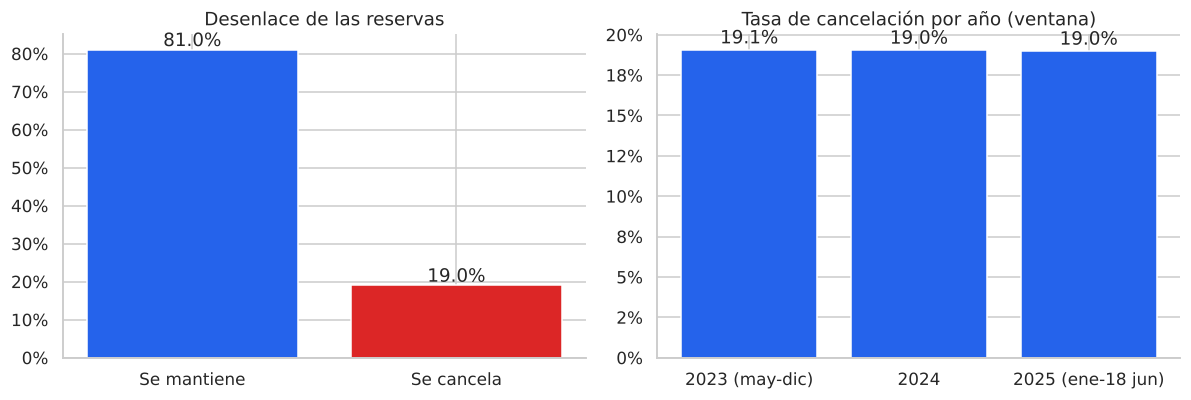

In [7]:
tasa_global = df.cancelada.mean()
perdido = df.ingreso_perdido.sum()
potencial = df.ingreso_potencial.sum()

k = pd.DataFrame({
    "Reservas": [f"{len(df):,}"],
    "Tasa de cancelación": [f"{tasa_global:.1%}"],
    "Ingreso potencial": [millones(potencial)],
    "Ingreso perdido por cancelaciones": [millones(perdido)],
    "% del potencial perdido": [f"{perdido/potencial:.1%}"],
})
display(k.T.rename(columns={0: "Valor"}))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
vc = df.cancelada.value_counts(normalize=True).sort_index()
ax[0].bar(["Se mantiene", "Se cancela"], vc.values, color=[AZUL, ROJO]); pct(ax[0]); ax[0].set_title("Desenlace de las reservas")
for i, v in enumerate(vc.values): ax[0].text(i, v + .01, f"{v:.1%}", ha="center")
aa = dv.groupby("anio_llegada").cancelada.mean()
ax[1].bar(["2023 (may-dic)", "2024", "2025 (ene-18 jun)"], aa.values, color=AZUL); pct(ax[1]); ax[1].set_title("Tasa de cancelación por año (ventana)")
for i, v in enumerate(aa.values): ax[1].text(i, v + .004, f"{v:.1%}", ha="center")
plt.tight_layout(); plt.show()

**Lectura.** Aproximadamente **1 de cada 5 reservas se cancela** (19,0 %) y esas cancelaciones representan $15,511 M de $81,694 M de ingreso potencial. La tasa se mantiene **estable** año a año (19,1 % en 2023, 19,0 % en 2024 y 19,0 % en 2025): el problema es persistente, no el efecto de un periodo puntual.

### 4.2 Distribución de las variables numéricas

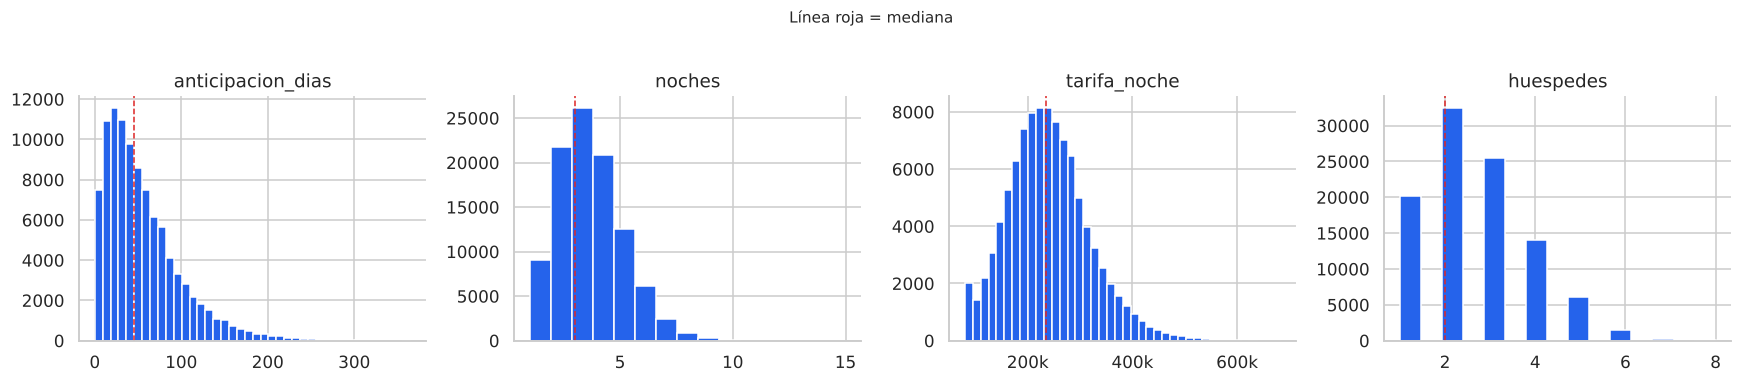

In [8]:
num = ["anticipacion_dias", "noches", "tarifa_noche", "huespedes"]
fig, axs = plt.subplots(1, 4, figsize=(16, 3.4))
for a, c in zip(axs, num):
    a.hist(df[c], bins=40 if c in ("anticipacion_dias", "tarifa_noche") else 15, color=AZUL, edgecolor="white")
    a.set_title(c); a.axvline(df[c].median(), color=ROJO, ls="--", lw=1)
axs[2].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, p: f"{x/1e3:.0f}k"))
plt.suptitle("Línea roja = mediana", y=1.02, fontsize=10); plt.tight_layout(); plt.show()

**Lectura.** `anticipacion_dias` y `noches` están sesgadas a la derecha (la mayoría reserva con 1-3 meses y se queda 2-4 noches; hay colas largas). La tarifa se concentra entre ~190 k y ~290 k COP por noche y depende sobre todo del tipo de habitación.

### 4.3 Composición de las reservas

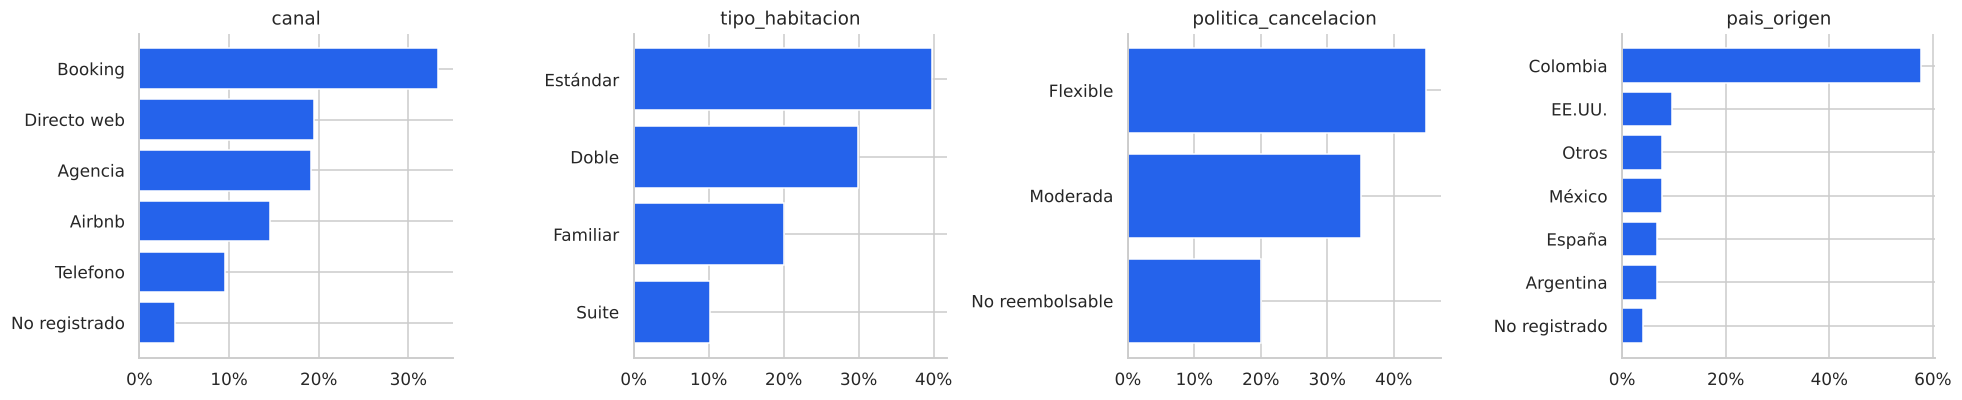

In [9]:
cats = ["canal", "tipo_habitacion", "politica_cancelacion", "pais_origen"]
fig, axs = plt.subplots(1, 4, figsize=(18, 3.8))
for a, c in zip(axs, cats):
    s = df[c].value_counts(normalize=True)
    a.barh(s.index[::-1], s.values[::-1], color=AZUL); pct(a, "x"); a.set_title(c)
plt.tight_layout(); plt.show()

**Lectura.** **Booking es el canal más grande (33,3 % de las reservas)**, tal como anticipa el caso. La política Flexible es la más usada (44,9 %). Cerca de la mitad de las reservas (47,0 %) llega con pago anticipado; saber si eso protege al hotel es justamente la pregunta 2.

### 4.4 ¿Qué variables se relacionan con cancelar? (visión global)

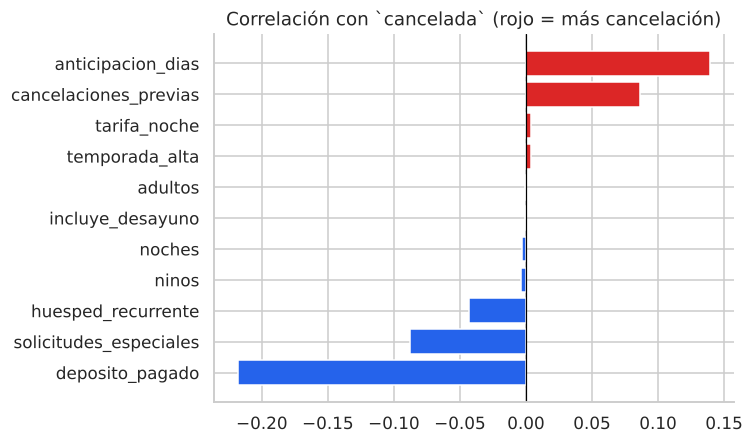

In [10]:
cols = ["anticipacion_dias", "noches", "adultos", "ninos", "tarifa_noche", "deposito_pagado", "huesped_recurrente",
        "solicitudes_especiales", "cancelaciones_previas", "incluye_desayuno", "temporada_alta"]
corr = df[cols + ["cancelada"]].corr()["cancelada"].drop("cancelada").sort_values()

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(corr.index, corr.values, color=[ROJO if v > 0 else AZUL for v in corr.values])
ax.axvline(0, color="black", lw=.8); ax.set_title("Correlación con `cancelada` (rojo = más cancelación)")
plt.tight_layout(); plt.show()

**Lectura.** Las señales más fuertes son: **anticipación** (+), **cancelaciones previas** (+) y **depósito pagado** (−). La composición del grupo (adultos, niños, noches), la tarifa y la temporada pesan poco. El tipo de política (categórica) no aparece aquí y se estudia en la pregunta 2.

### 4.5 El periodo atípico de 2023: ¿se ve la promoción?

In [11]:
a23 = (dv.assign(anio=dv.fecha_llegada.dt.year)
         .groupby("anio")
         .agg(reservas=("cancelada", "size"),
              tarifa_media=("tarifa_noche", "mean"),
              pct_tarifa_baja=("tarifa_noche", lambda s: (s < 130_000).mean()),
              pct_flexible=("politica_cancelacion", lambda s: (s == "Flexible").mean()),
              pct_booking=("canal", lambda s: (s == "Booking").mean()),
              pct_deposito=("deposito_pagado", "mean"),
              anticipacion_media=("anticipacion_dias", "mean"),
              tasa_cancelacion=("cancelada", "mean")))
a23.index = ["2023 (may-dic)", "2024", "2025 (ene-18 jun)"]
a23.style.format({"reservas": "{:,.0f}", "tarifa_media": "${:,.0f}", "pct_tarifa_baja": "{:.1%}", "pct_flexible": "{:.1%}",
                  "pct_booking": "{:.1%}", "pct_deposito": "{:.1%}", "anticipacion_media": "{:.1f}", "tasa_cancelacion": "{:.1%}"})

,reservas,tarifa_media,pct_tarifa_baja,pct_flexible,pct_booking,pct_deposito,anticipacion_media,tasa_cancelacion
2023 (may-dic),"26,843","$241,057",6.2%,44.8%,33.6%,47.1%,53.6,19.1%
2024,"40,745","$240,057",6.4%,44.8%,33.5%,46.7%,55.9,19.0%
2025 (ene-18 jun),"18,580","$238,219",6.6%,45.1%,33.1%,47.4%,55.5,19.0%


**Lectura.** El caso advierte que 2023 tuvo promociones, pero **en estos datos no hay una huella visible**: la tarifa media ($241.057, $240.057 y $238.219), la proporción de tarifas bajas (6,2 %, 6,4 %, 6,6 %), la mezcla de políticas y la de canales son casi idénticas en los tres años. La tasa de cancelación también es estable (19,1 %, 19,0 %, 19,0 %); lo único que cambia en 2023 es la rampa de arranque de enero a abril (sección 2.3), que ya está excluida de esta ventana. **Conclusión:** la promoción no se puede aislar con las variables disponibles; se declara como limitación y la fase técnica debe comprobar la robustez del modelo entrenando con y sin 2023.

### 4.6 Temporada alta (jun-jul y dic-ene)

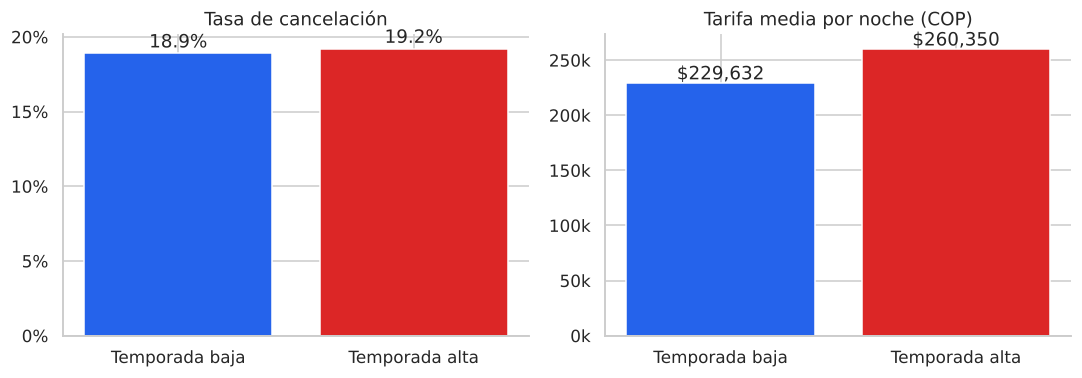

In [12]:
ta = df.groupby("temporada_alta").agg(tasa=("cancelada", "mean"), tarifa=("tarifa_noche", "mean"), reservas=("cancelada", "size"))
ta.index = ["Temporada baja", "Temporada alta"]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(ta.index, ta.tasa, color=[AZUL, ROJO]); pct(ax[0]); ax[0].set_title("Tasa de cancelación")
for i, v in enumerate(ta.tasa): ax[0].text(i, v + .004, f"{v:.1%}", ha="center")
ax[1].bar(ta.index, ta.tarifa, color=[AZUL, ROJO]); ax[1].set_title("Tarifa media por noche (COP)")
ax[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, p: f"{x/1e3:.0f}k"))
for i, v in enumerate(ta.tarifa): ax[1].text(i, v + 3000, f"${v:,.0f}", ha="center")
plt.tight_layout(); plt.show()

**Lectura.** El caso dice que la temporada alta presiona tarifas y comportamiento. Los datos confirman lo primero (la tarifa media sube 13 %) pero **no lo segundo**: la tasa de cancelación es prácticamente la misma (19,2 % en temporada alta vs. 18,9 % en baja). La temporada mueve el *precio*, no el *riesgo de cancelar*.

## 5. Pregunta 1 · ¿Se pueden anticipar las cancelaciones para aceptar reservas adicionales?

**Qué necesitamos ver en los datos** para que aceptar reservas por encima de la capacidad del hotel (sobreventa controlada) tenga sentido:
1. Que el número de cancelaciones **por noche** sea **estable y predecible** (no puramente errático).
2. Que sea **explicable** por el volumen de reservas y por factores observables.
3. Que exista una **cola** conocida (cuántas cancelaciones ocurren casi siempre), pues el OKR se apoya en el percentil 10 de las cancelaciones esperadas.

**Unidad de análisis: la noche de llegada.** Cada reserva se cuenta una sola vez, en la noche en que el huésped debía llegar (`fecha_llegada`). Es la unidad en la que el PDF define su año de prueba: del 1-jul-2024 al 18-jun-2025 hay exactamente **353 noches de llegada**, y un error de 3,0 cancelaciones por noche es consistente con ella (el ruido inevitable de esta unidad ronda las 3 cancelaciones; ver la prueba más abajo).

In [13]:
diario = (dv.groupby("fecha_llegada")
            .agg(reservas=("cancelada", "size"), cancelaciones=("cancelada", "sum"))
            .reset_index())
diario["tasa"] = diario.cancelaciones / diario.reservas
diario["mes"] = diario.fecha_llegada.dt.month
diario["dia_semana"] = diario.fecha_llegada.dt.dayofweek

print(f"Noches de llegada analizadas: {len(diario):,} (del {diario.fecha_llegada.min().date()} al {diario.fecha_llegada.max().date()})")
display(diario[["reservas", "cancelaciones", "tasa"]].describe().T)
c = diario.cancelaciones
print(f"\nCancelaciones por noche: media = {c.mean():.1f} | desviación = {c.std():.1f} | coef. de variación = {c.std()/c.mean():.0%}")

Noches de llegada analizadas: 780 (del 2023-05-01 al 2025-06-18)


,count,mean,std,min,25%,50%,75%,max
reservas,780.00,110.47,10.63,82.00,103.00,110.00,117.00,145.00
cancelaciones,780.00,21.03,4.66,8.00,18.00,21.00,24.00,39.00
tasa,780.00,0.19,0.04,0.09,0.17,0.19,0.21,0.31



Cancelaciones por noche: media = 21.0 | desviación = 4.7 | coef. de variación = 22%


**Lectura.** Cada noche de llegada se cancelan en promedio **21,0 reservas** (sobre ≈ 110 reservas por noche), con una desviación de 4,7 (coeficiente de variación 22 %): un nivel **estable**, no ruido sin estructura.

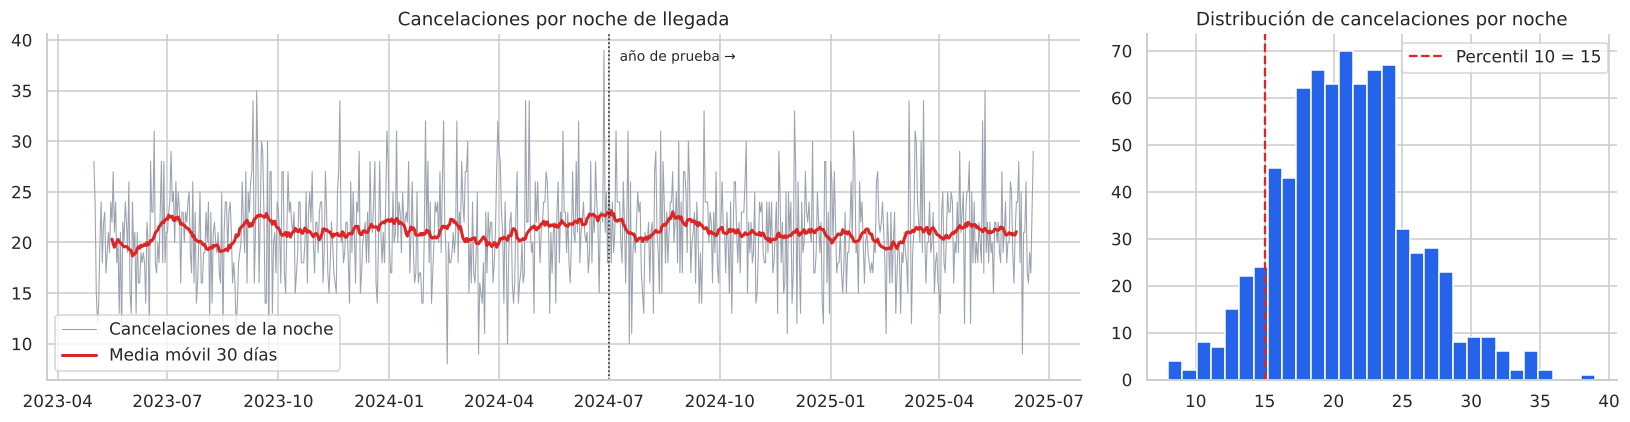

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].plot(diario.fecha_llegada, diario.cancelaciones, color=GRIS, lw=.7, label="Cancelaciones de la noche")
ax[0].plot(diario.fecha_llegada, diario.cancelaciones.rolling(30, center=True).mean(), color=ROJO, lw=2, label="Media móvil 30 días")
ax[0].axvline(pd.Timestamp("2024-07-01"), color="k", ls=":", lw=1)
ax[0].text(pd.Timestamp("2024-07-10"), diario.cancelaciones.max(), "año de prueba →", va="top", fontsize=9)
ax[0].set_title("Cancelaciones por noche de llegada"); ax[0].legend(loc="lower left")
ax[1].hist(diario.cancelaciones, bins=30, color=AZUL, edgecolor="white")
p10 = diario.cancelaciones.quantile(.10)
ax[1].axvline(p10, color=ROJO, ls="--", label=f"Percentil 10 = {p10:.0f}"); ax[1].legend()
ax[1].set_title("Distribución de cancelaciones por noche")
plt.tight_layout(); plt.show()

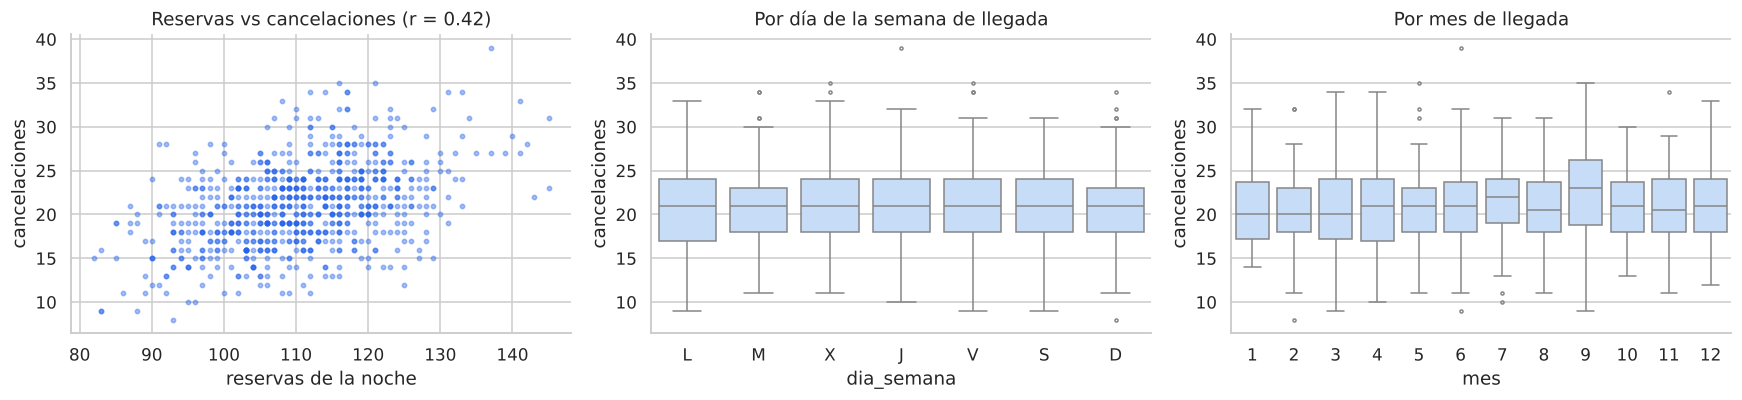

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].scatter(diario.reservas, diario.cancelaciones, s=8, alpha=.4, color=AZUL)
r_dia = diario[["reservas", "cancelaciones"]].corr().iloc[0, 1]
ax[0].set_title(f"Reservas vs cancelaciones (r = {r_dia:.2f})"); ax[0].set_xlabel("reservas de la noche"); ax[0].set_ylabel("cancelaciones")
sns.boxplot(data=diario, x="dia_semana", y="cancelaciones", color="#bfdbfe", ax=ax[1], fliersize=2)
ax[1].set_xticklabels(["L", "M", "X", "J", "V", "S", "D"]); ax[1].set_title("Por día de la semana de llegada")
sns.boxplot(data=diario, x="mes", y="cancelaciones", color="#bfdbfe", ax=ax[2], fliersize=2)
ax[2].set_title("Por mes de llegada")
plt.tight_layout(); plt.show()

**Lectura.** Las cancelaciones **crecen con las reservas programadas esa noche** (r = 0,42): la señal principal es el volumen en cartera, no un patrón semanal o mensual marcado. Por eso conviene modelar la **tasa** de cancelación y multiplicarla por las reservas en cartera, en vez de predecir un número fijo.

### Prueba rápida: ¿predecir con la cartera supera a usar un promedio fijo? ¿Y cuál es el límite?

In [16]:
corte = pd.Timestamp("2024-07-01")                  # entrenamiento: antes / prueba: 1-jul-2024 → 18-jun-2025
tr, te = diario[diario.fecha_llegada < corte], diario[diario.fecha_llegada >= corte]
tasa_tr = tr.cancelaciones.sum() / tr.reservas.sum()

mae_fijo = (te.cancelaciones - tr.cancelaciones.mean()).abs().mean()
mae_tasa = (te.cancelaciones - te.reservas * tasa_tr).abs().mean()

# Piso de ruido: aunque se conociera la probabilidad exacta de cada reserva, cada cancelación es un evento aleatorio.
# Si las cancelaciones fueran independientes, su desviación sería √(Σ p(1−p)) y el error absoluto medio ≈ 0,8 × esa desviación.
piso_ruido = 0.798 * np.sqrt((te.reservas * tasa_tr * (1 - tasa_tr)).mean())

print(f"Noches de entrenamiento: {len(tr)} | noches de prueba: {len(te)}")
pd.DataFrame({
    "Enfoque": ["A. Promedio histórico fijo", "B. Tasa histórica × reservas de la noche", "Piso de ruido (error inevitable)"],
    "Error absoluto medio (cancelaciones/noche)": [mae_fijo, mae_tasa, piso_ruido],
}).set_index("Enfoque")

Noches de entrenamiento: 427 | noches de prueba: 353


,Error absoluto medio (cancelaciones/noche)
Enfoque,
A. Promedio histórico fijo,3.62
B. Tasa histórica × reservas de la noche,3.24
Piso de ruido (error inevitable),3.30


**Lectura.** En las **353 noches de prueba** del PDF, la regla simple (tasa histórica × reservas de la noche) tiene un error de **3,24 cancelaciones por noche**, frente a 3,62 del promedio fijo. El **piso de ruido** (el error que queda aunque la tasa fuera exacta y igual para todas las reservas) es de ≈ 3,3, y la regla simple ya está prácticamente ahí. La meta del PDF (3,0) queda apenas por debajo, así que es **ambiciosa pero coherente con los datos**: solo se alcanza si el modelo distingue bien las reservas de alto y bajo riesgo, porque eso reduce el ruido inevitable. Esto también explica por qué la fase técnica debe fijar el colchón de reservas adicionales con un **percentil bajo** (el OKR usa el 10) y no con la media.

### Escala frente a capacidad

Para comparar con la capacidad real del hotel hay que contar **noches ocupadas**: una reserva de 3 noches ocupa tres noches, no una.

In [17]:
def noches_por_dia(d):
    # Convierte cada reserva en una fila por noche de estancia y cuenta cuántas hay en cada fecha
    rep = d.loc[d.index.repeat(d["noches"])]
    desfase = np.concatenate([np.arange(n) for n in d["noches"]])
    fechas = rep["fecha_llegada"].values + pd.to_timedelta(desfase, unit="D").values
    return pd.Series(1, index=pd.DatetimeIndex(fechas)).groupby(level=0).sum()

rango = pd.date_range("2024-07-01", FIN_VENTANA)                   # el año de prueba
cand = df[df.fecha_llegada.between(pd.Timestamp("2024-06-16"), FIN_VENTANA)]   # estancias que llegan antes pero cubren el año
nd = pd.DataFrame({
    "reservadas": noches_por_dia(cand).reindex(rango, fill_value=0),
    "canceladas": noches_por_dia(cand[cand.cancelada == 1]).reindex(rango, fill_value=0),
})
nd["confirmadas"] = nd.reservadas - nd.canceladas

print(f"Noches del año de prueba: {len(nd)}")
display(nd.describe().T[["mean", "std", "min", "max"]])
print(f"\nHabitaciones ocupadas (confirmadas) por noche: media = {nd.confirmadas.mean():.0f} | máximo = {nd.confirmadas.max():.0f}")
print(f"El hotel tiene {HABITACIONES} habitaciones → la base equivale a {nd.confirmadas.mean()/HABITACIONES:.1f} veces su capacidad")

Noches del año de prueba: 353


,mean,std,min,max
reservadas,378.79,20.80,322.00,432.00
canceladas,71.86,7.59,51.00,95.00
confirmadas,306.93,19.44,251.00,360.00



Habitaciones ocupadas (confirmadas) por noche: media = 307 | máximo = 360
El hotel tiene 38 habitaciones → la base equivale a 8.1 veces su capacidad


> **Escala frente a capacidad.** En el año de prueba la base tiene en promedio **307 habitaciones ocupadas por noche** (máximo 360), unas **8,1 veces las 38 habitaciones** del caso. Los datos representan una escala mayor que la narrada. Por eso la fase técnica debe fijar un supuesto explícito de capacidad (por ejemplo, escalar todo por ≈ 8,1) y expresar las incidencias por falta de habitación en términos relativos.

## 6. Pregunta 2 · ¿Qué clientes cancelan más y cuánta plata se ahorra con pago anticipado focalizado?

Para sostener la pregunta necesitamos mostrar: (a) que el pago anticipado se asocia con menos cancelación **una vez descontado el efecto de la política**; (b) que el riesgo **no es homogéneo** (hay perfiles claramente más riesgosos, lo que justifica focalizar en vez de exigir depósito a todos); (c) que el dinero en juego es material.

### 6.1 Pago anticipado y política de cancelación

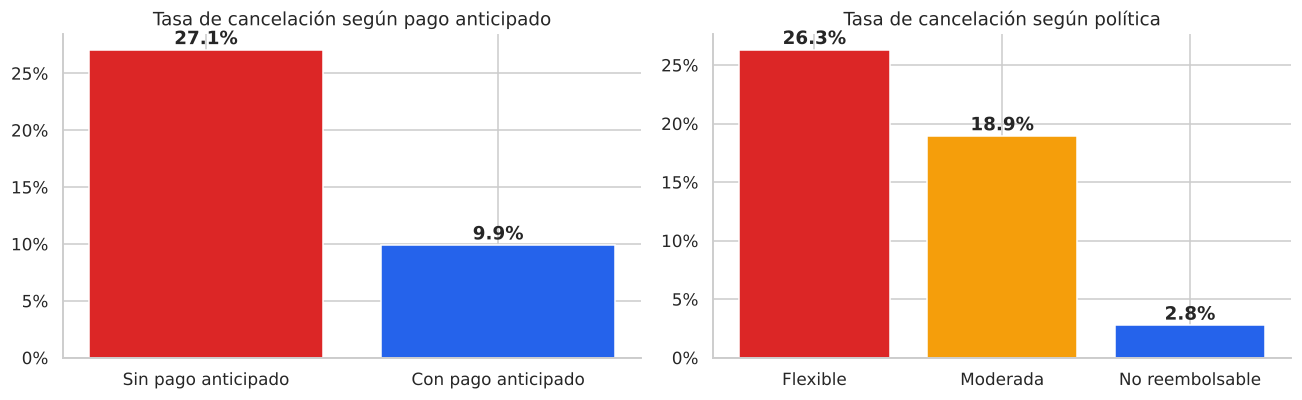

% de reservas con depósito, por política:


,con depósito
politica_cancelacion,
Flexible,35.0%
Moderada,35.0%
No reembolsable,94.9%


In [18]:
t_dep = df.groupby("deposito_pagado").cancelada.agg(["mean", "size"])
t_dep.index = ["Sin pago anticipado", "Con pago anticipado"]
pol = df.groupby("politica_cancelacion").cancelada.mean().sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(t_dep.index, t_dep["mean"], color=[ROJO, AZUL]); pct(ax[0]); ax[0].set_title("Tasa de cancelación según pago anticipado")
for i, v in enumerate(t_dep["mean"]): ax[0].text(i, v + .005, f"{v:.1%}", ha="center", fontweight="bold")
ax[1].bar(pol.index, pol.values, color=[ROJO, "#f59e0b", AZUL]); pct(ax[1]); ax[1].set_title("Tasa de cancelación según política")
for i, v in enumerate(pol.values): ax[1].text(i, v + .005, f"{v:.1%}", ha="center", fontweight="bold")
plt.tight_layout(); plt.show()

print("% de reservas con depósito, por política:")
display(df.groupby("politica_cancelacion").deposito_pagado.mean().map("{:.1%}".format).to_frame("con depósito"))

**Lectura (primera aproximación).** Quienes pagan por adelantado cancelan ≈ 2,7 veces menos (27,1 % vs. 9,9 %). **Pero esta cifra mezcla dos efectos:** el 95 % de las reservas No reembolsables ya viene con depósito y casi no cancela. Hay que separar el efecto del depósito dentro de cada política.

### 6.1b El efecto del depósito, descontando la política

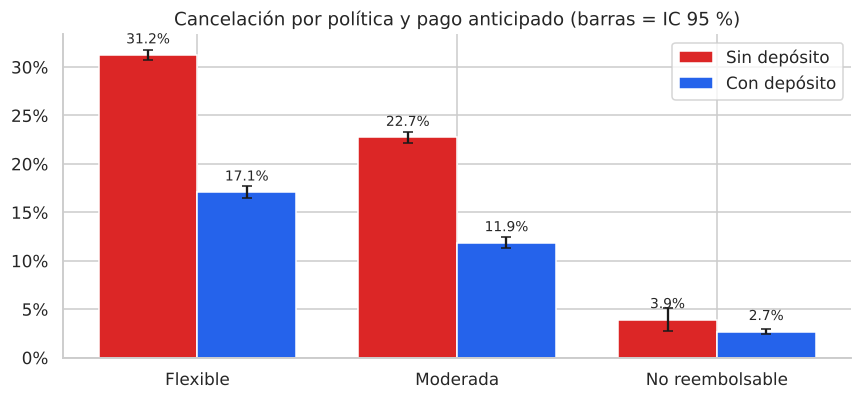

Flexible + Moderada  sin depósito: 27.5% ± 0.4%  |  con depósito: 14.8% ± 0.4%  →  razón = 1.86
No reembolsable sin depósito: solo 1,021 reservas
Chi-cuadrado · depósito (global)              p = 0.00e+00
Chi-cuadrado · depósito en Flexible+Moderada  p = 0.00e+00
Chi-cuadrado · canal                          p = 0.00e+00
Chi-cuadrado · política                       p = 0.00e+00


In [19]:
g = df.groupby(["politica_cancelacion", "deposito_pagado"]).cancelada.agg(["mean", "size"]).reset_index()
g["ic"] = ic95(g["mean"], g["size"])
g["deposito"] = g.deposito_pagado.map({0: "Sin depósito", 1: "Con depósito"})

fig, ax = plt.subplots(figsize=(8, 3.8))
orden = ["Flexible", "Moderada", "No reembolsable"]
w = .38
for j, (dep, col) in enumerate([("Sin depósito", ROJO), ("Con depósito", AZUL)]):
    s = g[g.deposito == dep].set_index("politica_cancelacion").loc[orden]
    ax.bar(np.arange(3) + (j - .5) * w, s["mean"], w, yerr=s["ic"], color=col, label=dep, capsize=3)
    for i, v in enumerate(s["mean"]): ax.text(i + (j - .5) * w, v + .012, f"{v:.1%}", ha="center", fontsize=9)
ax.set_xticks(range(3)); ax.set_xticklabels(orden); pct(ax); ax.legend()
ax.set_title("Cancelación por política y pago anticipado (barras = IC 95 %)")
plt.tight_layout(); plt.show()

# Efecto del depósito SOLO en las políticas Flexible y Moderada
fm = df[df.politica_cancelacion != "No reembolsable"]
tfm = fm.groupby("deposito_pagado").cancelada.agg(["mean", "size"])
print(f"Flexible + Moderada  sin depósito: {tfm.loc[0, 'mean']:.1%} ± {ic95(tfm.loc[0, 'mean'], tfm.loc[0, 'size']):.1%}  |  con depósito: {tfm.loc[1, 'mean']:.1%} ± {ic95(tfm.loc[1, 'mean'], tfm.loc[1, 'size']):.1%}  →  razón = {tfm.loc[0, 'mean']/tfm.loc[1, 'mean']:.2f}")
print(f"No reembolsable sin depósito: solo {int(g[(g.politica_cancelacion=='No reembolsable') & (g.deposito_pagado==0)]['size'].iloc[0]):,} reservas")

# Pruebas de significancia (chi-cuadrado)
for nombre, a, b in [("depósito (global)", df.deposito_pagado, df.cancelada), ("depósito en Flexible+Moderada", fm.deposito_pagado, fm.cancelada),
                     ("canal", df.canal, df.cancelada), ("política", df.politica_cancelacion, df.cancelada)]:
    chi2, p, *_ = stats.chi2_contingency(pd.crosstab(a, b))
    print(f"Chi-cuadrado · {nombre:30s} p = {p:.2e}")

**Lectura.** Dentro de las políticas donde el depósito es una decisión (Flexible y Moderada) la brecha es **27,5 % vs. 14,8 %**, es decir **≈ 1,9 veces**, no ≈ 2,7: la cifra global de la sección anterior se infla porque casi toda la tarifa No reembolsable ya paga por adelantado y casi no cancela (2,8 %). Las diferencias son estadísticamente significativas (chi-cuadrado, p < 0,001) y sus intervalos de confianza no se solapan. El efecto sigue siendo grande, pero es la mitad de lo que sugería la comparación global.

Es **asociación, no causalidad**: quien deposita puede ser un huésped más comprometido. Por eso el PDF habla de ahorro *estimado* con el modelo, y por eso el modelo de P2 debe incluir la política.

### 6.2 ¿El riesgo es homogéneo? Perfiles de cancelación

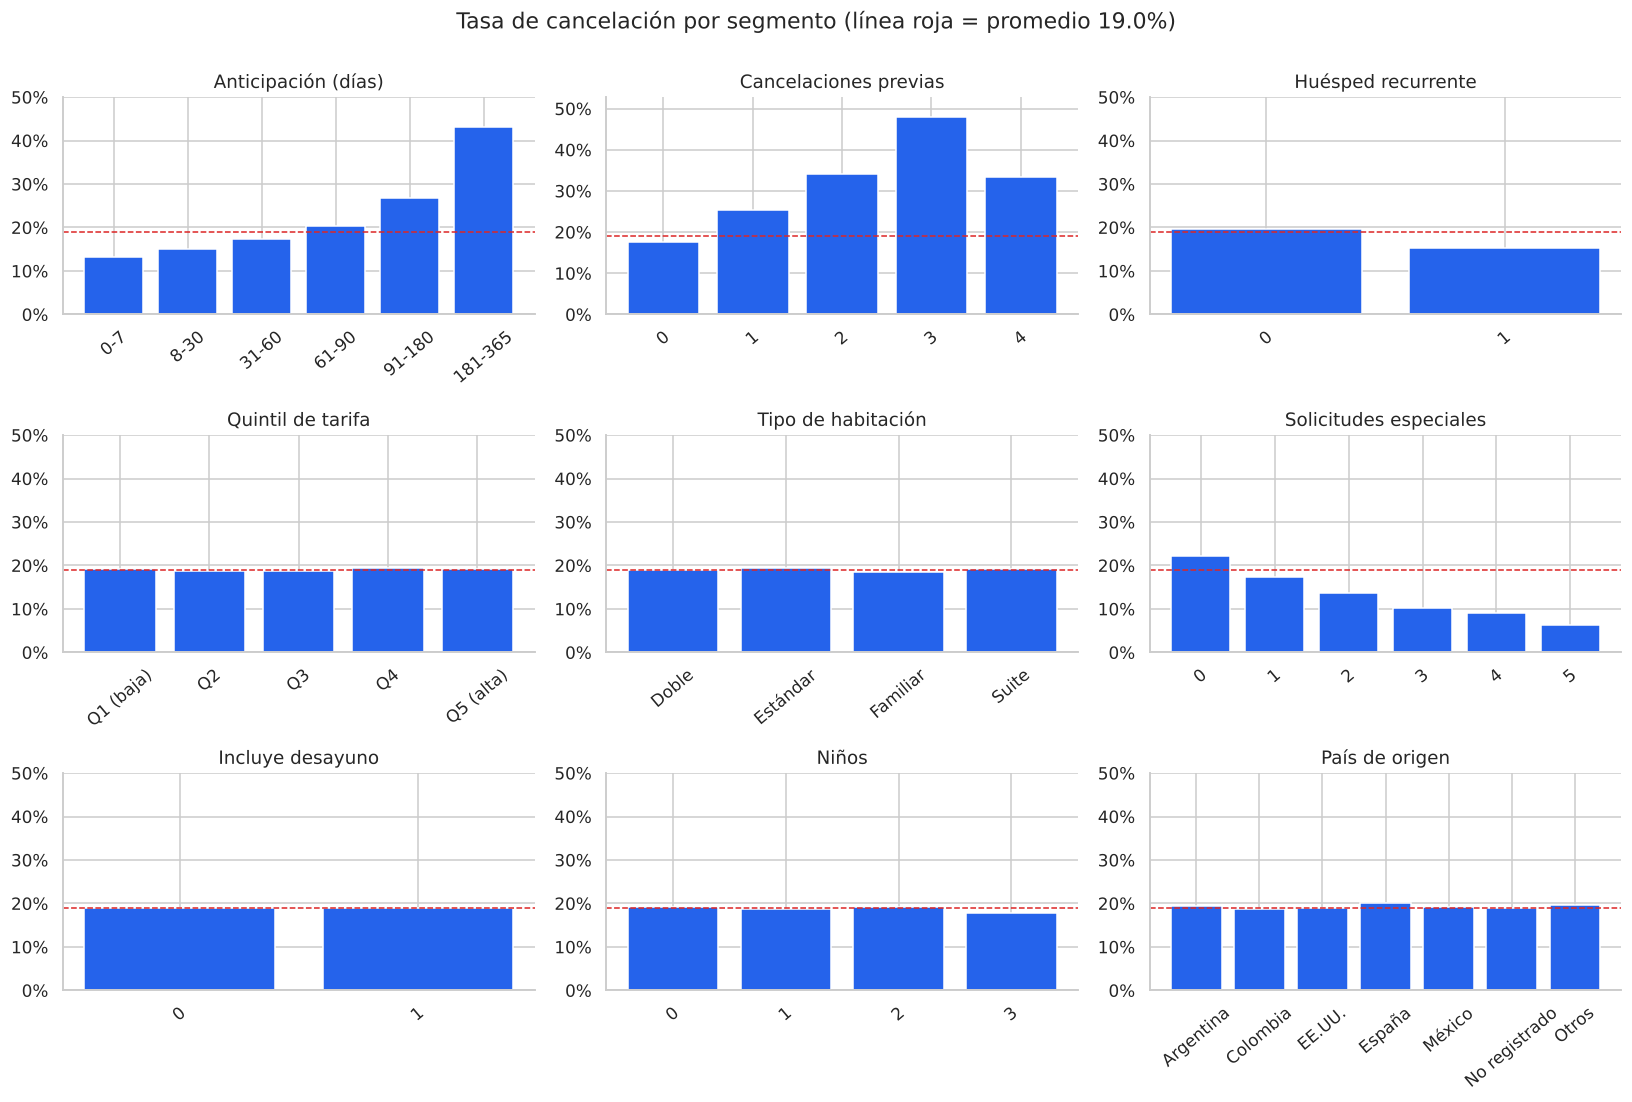

In [20]:
vars_perfil = [
    ("rango_anticipacion", "Anticipación (días)"),
    ("cancelaciones_previas", "Cancelaciones previas"),
    ("huesped_recurrente", "Huésped recurrente"),
    ("quintil_tarifa", "Quintil de tarifa"),
    ("tipo_habitacion", "Tipo de habitación"),
    ("solicitudes_especiales", "Solicitudes especiales"),
    ("incluye_desayuno", "Incluye desayuno"),
    ("ninos", "Niños"),
    ("pais_origen", "País de origen"),
]
fig, axs = plt.subplots(3, 3, figsize=(15, 10))
for a, (c, t) in zip(axs.ravel(), vars_perfil):
    s = df.groupby(c, observed=True).cancelada.mean()
    a.bar(s.index.astype(str), s.values, color=AZUL); a.axhline(tasa_global, color=ROJO, ls="--", lw=1)
    a.set_title(t); pct(a); a.tick_params(axis="x", rotation=40); a.set_ylim(0, max(.5, s.max() * 1.1))
plt.suptitle(f"Tasa de cancelación por segmento (línea roja = promedio {tasa_global:.1%})", y=1.0)
plt.tight_layout(); plt.show()

**Lectura.**
- La **anticipación** es el factor más marcante: de 13,2 % en reservas de última hora a 43,2 % en las de más de 6 meses.
- Las **cancelaciones previas** elevan el riesgo de forma casi escalonada (17,6 % sin historial → 34,1 % con dos).
- Huésped recurrente cancela menos.
- **El precio no explica la cancelación:** la tasa es prácticamente igual en los cinco quintiles de tarifa (18,6 % a 19,3 %). Subir o bajar tarifas no parece una palanca para reducir cancelaciones; sí lo son la política, el depósito y el canal.
- Tipo de habitación, desayuno, país o niños casi no discriminan.

El riesgo está **concentrado en perfiles identificables** → tiene sentido focalizar el depósito en lugar de exigirlo a todos.

### 6.3 Combinación de factores: dónde se concentra el riesgo

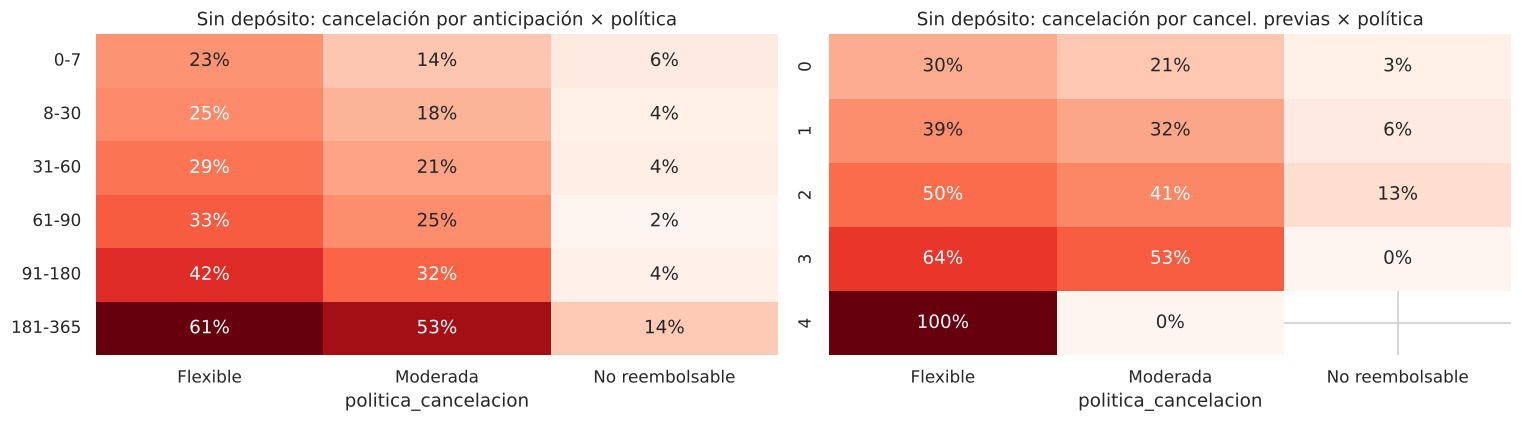

In [21]:
sin_dep = df[df.deposito_pagado == 0]
pv = sin_dep.pivot_table(index="rango_anticipacion", columns="politica_cancelacion", values="cancelada", aggfunc="mean", observed=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(pv, annot=True, fmt=".0%", cmap="Reds", ax=ax[0], cbar=False)
ax[0].set_title("Sin depósito: cancelación por anticipación × política"); ax[0].set_ylabel("")
pv2 = sin_dep.pivot_table(index="cancelaciones_previas", columns="politica_cancelacion", values="cancelada", aggfunc="mean")
sns.heatmap(pv2, annot=True, fmt=".0%", cmap="Reds", ax=ax[1], cbar=False)
ax[1].set_title("Sin depósito: cancelación por cancel. previas × política"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

**Lectura.** La combinación **política flexible + mucha anticipación + historial de cancelaciones** alcanza tasas muy superiores al promedio, mientras que la tarifa no reembolsable queda cerca de cero. Hay un grupo reducido de reservas sin depósito que explica una parte desproporcionada de las pérdidas.

### 6.4 Señal predictiva preliminar y dinero en juego

In [22]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

feats_cat = ["tipo_habitacion", "canal", "pais_origen", "politica_cancelacion"]
feats_num = ["anticipacion_dias", "noches", "adultos", "ninos", "tarifa_noche", "deposito_pagado", "huesped_recurrente",
             "solicitudes_especiales", "cancelaciones_previas", "incluye_desayuno", "mes_llegada"]

# Se usa la ventana confiable (dv): entrena antes de jul-2024, evalúa jul-2024 → 18-jun-2025
y = dv.cancelada
es_tr = dv.fecha_llegada < "2024-07-01"

# Modelo A: gradient boosting
X = dv[feats_cat + feats_num].copy()
X[feats_cat] = OrdinalEncoder().fit_transform(X[feats_cat]).astype(int)
mod = HistGradientBoostingClassifier(max_iter=200, learning_rate=.08, random_state=SEMILLA,
                                     categorical_features=[X.columns.get_loc(c) for c in feats_cat])
mod.fit(X[es_tr], y[es_tr])
proba = pd.Series(mod.predict_proba(X[~es_tr])[:, 1], index=X[~es_tr].index)

# Modelo B: regresión logística (referencia simple)
XL = pd.get_dummies(dv[feats_cat + feats_num], columns=feats_cat, drop_first=True).astype(float)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEMILLA)).fit(XL[es_tr], y[es_tr])
auc_gbm = roc_auc_score(y[~es_tr], proba)
auc_lr = roc_auc_score(y[~es_tr], lr.predict_proba(XL[~es_tr])[:, 1])
print(f"AUC en la prueba (1-jul-2024 → 18-jun-2025) · gradient boosting: {auc_gbm:.3f} | regresión logística: {auc_lr:.3f}   [0.5 = azar, 1 = perfecto]")

te_df = dv[~es_tr].assign(p=proba)
te_sin = te_df[te_df.deposito_pagado == 0]
alto = te_sin[te_sin.p > .30]
print(f"\nEn el año de prueba, sin pago anticipado: {len(te_sin):,} reservas")
print(f"  · clasificadas de alto riesgo (p > 30 %): {len(alto):,} ({len(alto)/len(te_sin):.0%})")
print(f"  · su tasa real de cancelación: {alto.cancelada.mean():.1%} vs {te_sin[te_sin.p <= .30].cancelada.mean():.1%} en el resto")
print(f"  · ingreso perdido en esas reservas de alto riesgo: {millones(alto.ingreso_perdido.sum())} "
      f"({alto.ingreso_perdido.sum()/te_sin.ingreso_perdido.sum():.0%} de lo perdido en reservas sin depósito)")

AUC en la prueba (1-jul-2024 → 18-jun-2025) · gradient boosting: 0.770 | regresión logística: 0.776   [0.5 = azar, 1 = perfecto]

En el año de prueba, sin pago anticipado: 20,726 reservas
  · clasificadas de alto riesgo (p > 30 %): 7,670 (37%)
  · su tasa real de cancelación: 42.8% vs 17.7% en el resto
  · ingreso perdido en esas reservas de alto riesgo: $2,703 M (59% de lo perdido en reservas sin depósito)


**Lectura.** Un modelo genérico, sin ajustes, **ya discrimina bien** (AUC 0,770 con gradient boosting y 0,776 con regresión logística, muy por encima de 0,5) y valida con datos «futuros» respecto al entrenamiento. Que ambos modelos den resultados parecidos indica que la señal es robusta y no depende de un algoritmo en particular. Un segmento minoritario de reservas sin depósito (37 %) concentra una parte mayor de las pérdidas (59 %), y es allí donde pedir pago anticipado tendría más retorno. Es una **prueba de viabilidad**; el modelo definitivo, su calibración y el cálculo del ahorro en pesos corresponden a la fase técnica.

## 7. Pregunta 3 · Políticas por canal (Booking y Airbnb)

Necesitamos evidenciar que (a) los canales **difieren** en cancelación y en el dinero que pierden, (b) esa diferencia **no se explica solo por la mezcla de políticas**, y (c) existe margen de mejora plausible al pasar Flexible → Moderada o exigir depósito.

### 7.1 Canales: volumen, cancelación y dinero perdido

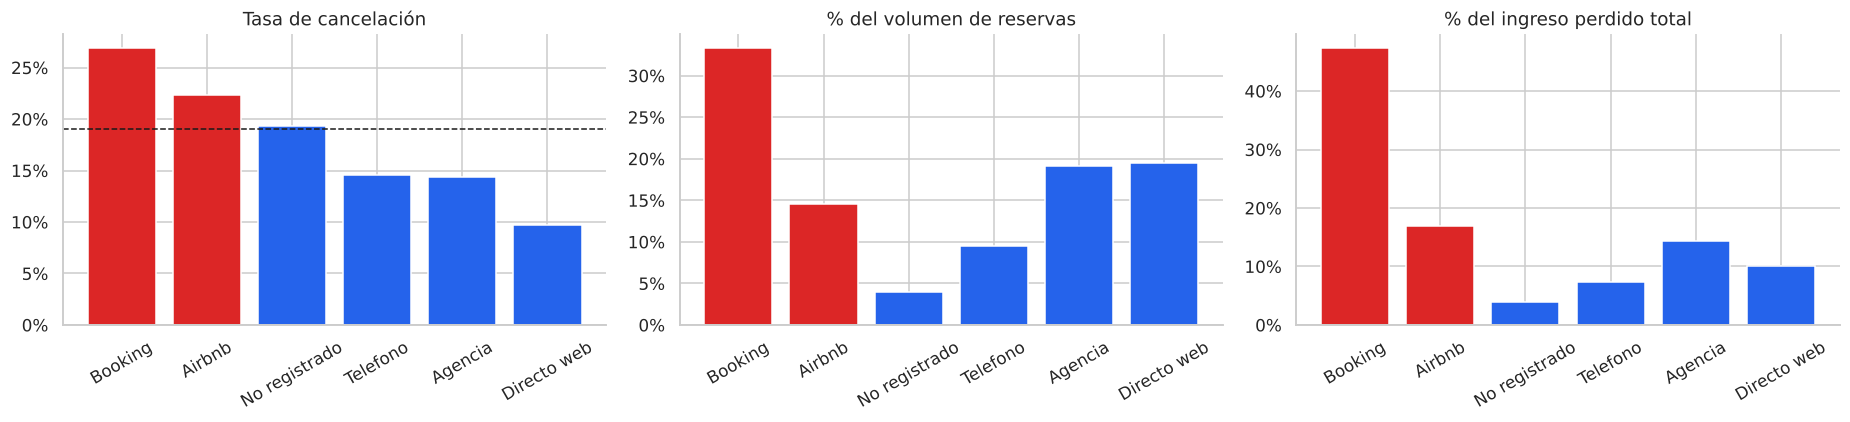

,reservas,tasa,share_vol,share_perdido
canal,,,,
Booking,"33,298",26.9%,33.3%,47.3%
Airbnb,"14,521",22.3%,14.5%,16.8%
No registrado,"4,014",19.4%,4.0%,4.0%
Telefono,"9,554",14.6%,9.6%,7.4%
Agencia,"19,111",14.4%,19.1%,14.4%
Directo web,"19,502",9.7%,19.5%,10.1%


In [23]:
canal = (df.groupby("canal")
           .agg(reservas=("cancelada", "size"), tasa=("cancelada", "mean"), perdido=("ingreso_perdido", "sum"))
           .assign(share_vol=lambda d: d.reservas / d.reservas.sum(),
                   share_perdido=lambda d: d.perdido / d.perdido.sum())
           .sort_values("tasa", ascending=False))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
cols_c = [ROJO if c in ("Booking", "Airbnb") else AZUL for c in canal.index]
ax[0].bar(canal.index, canal.tasa, color=cols_c); pct(ax[0]); ax[0].axhline(tasa_global, color="k", ls="--", lw=1); ax[0].set_title("Tasa de cancelación")
ax[1].bar(canal.index, canal.share_vol, color=cols_c); pct(ax[1]); ax[1].set_title("% del volumen de reservas")
ax[2].bar(canal.index, canal.share_perdido, color=cols_c); pct(ax[2]); ax[2].set_title("% del ingreso perdido total")
for a in ax: a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

canal[["reservas", "tasa", "share_vol", "share_perdido"]].style.format(
    {"reservas": "{:,.0f}", "tasa": "{:.1%}", "share_vol": "{:.1%}", "share_perdido": "{:.1%}"})

**Lectura.** **Booking** (26,9 %) y **Airbnb** (22,3 %) superan el promedio (19,0 %), mientras que Directo web (9,7 %) es el canal más «sano». Booking concentra 33,3 % del volumen pero **cerca de la mitad del ingreso perdido** (47 %). Airbnb es el segundo foco (17 %).

### 7.2 ¿Es un tema de política o es el canal?

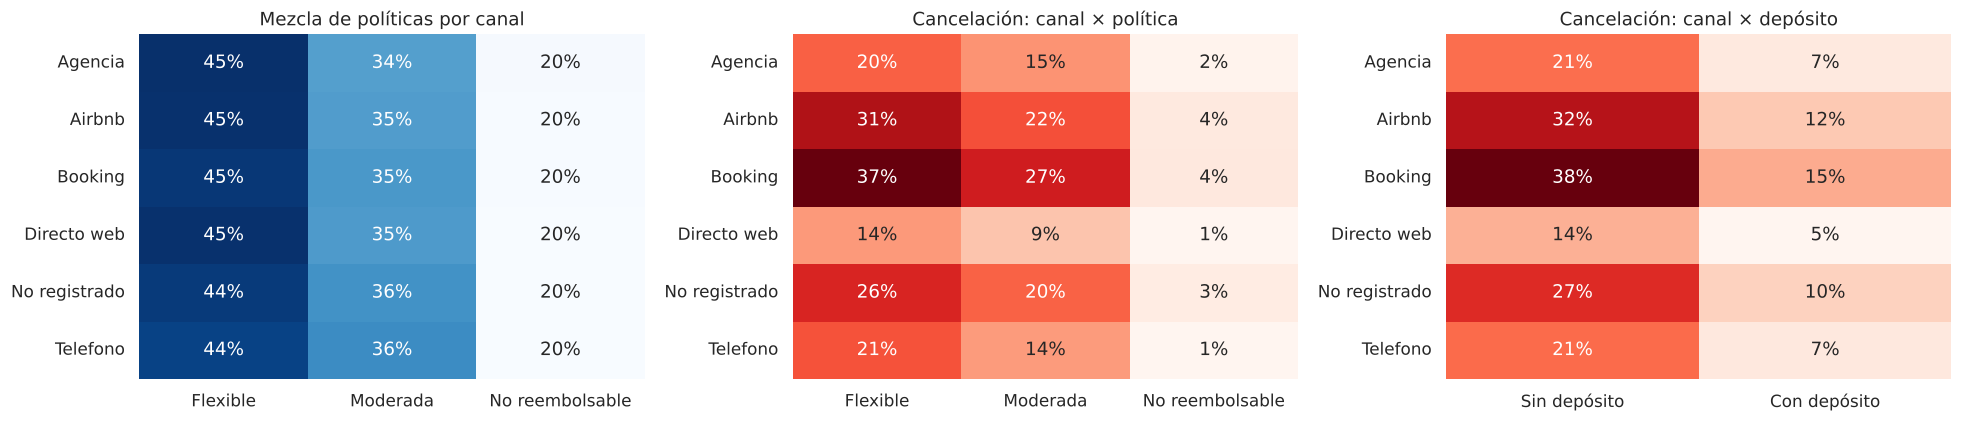

In [24]:
mix = pd.crosstab(df.canal, df.politica_cancelacion, normalize="index")
tasa_cp = df.pivot_table(index="canal", columns="politica_cancelacion", values="cancelada", aggfunc="mean")
tasa_cd = df.pivot_table(index="canal", columns="deposito_pagado", values="cancelada", aggfunc="mean").rename(columns={0: "Sin depósito", 1: "Con depósito"})

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
sns.heatmap(mix, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax[0]); ax[0].set_title("Mezcla de políticas por canal")
sns.heatmap(tasa_cp, annot=True, fmt=".0%", cmap="Reds", cbar=False, ax=ax[1]); ax[1].set_title("Cancelación: canal × política")
sns.heatmap(tasa_cd, annot=True, fmt=".0%", cmap="Reds", cbar=False, ax=ax[2]); ax[2].set_title("Cancelación: canal × depósito")
for a in ax: a.set_ylabel(""); a.set_xlabel("")
plt.tight_layout(); plt.show()

**Lectura.**
- La **mezcla de políticas es casi idéntica en todos los canales** (≈ 45 % Flexible / 35 % Moderada / 20 % No reembolsable). Por tanto, la mayor cancelación de Booking y Airbnb **no se debe a que usen más políticas flexibles**: es comportamiento propio del canal.
- Dentro de cada canal, pasar de Flexible a Moderada baja la cancelación, y el depósito la reduce aún más. En Booking: Flexible sin depósito ≈ 43,2 %, Moderada sin depósito ≈ 32,5 % y Flexible con depósito ≈ 24,7 %.

### 7.3 Escenario exploratorio: ¿cuánto bajaría la cancelación en Booking y Airbnb?

In [25]:
# Tasas observadas por celda canal × política × depósito
cel = df.groupby(["canal", "politica_cancelacion", "deposito_pagado"]).cancelada.mean()

filas = []
for c in ["Booking", "Airbnb"]:
    base = df[df.canal == c]
    flex_sin = base[(base.politica_cancelacion == "Flexible") & (base.deposito_pagado == 0)]
    p_act = flex_sin.cancelada.mean()
    p_mod = cel[(c, "Moderada", 0)]            # Flexible → Moderada (sin depósito)
    p_dep = cel[(c, "Flexible", 1)]            # Flexible con depósito
    for nombre, p_new in [("Flexible → Moderada", p_mod), ("Flexible + depósito", p_dep)]:
        # tasa de canal si SOLO se cambia ese subconjunto
        n_canc_new = base.cancelada.sum() - flex_sin.cancelada.sum() + p_new * len(flex_sin)
        filas.append({
            "Canal": c, "Escenario": nombre, "Reservas afectadas": len(flex_sin),
            "Tasa actual (afectadas)": p_act, "Tasa escenario (afectadas)": p_new,
            "Tasa del canal hoy": base.cancelada.mean(), "Tasa del canal con la política": n_canc_new / len(base),
            "Ingreso recuperable": ((p_act - p_new) * flex_sin.ingreso_potencial.mean() * len(flex_sin)),
            "p_act": p_act, "p_new": p_new,
        })
esc = pd.DataFrame(filas)
esc.drop(columns=["p_act", "p_new"]).style.format({
    "Reservas afectadas": "{:,.0f}", "Tasa actual (afectadas)": "{:.1%}", "Tasa escenario (afectadas)": "{:.1%}",
    "Tasa del canal hoy": "{:.1%}", "Tasa del canal con la política": "{:.1%}", "Ingreso recuperable": lambda v: millones(v)})

,Canal,Escenario,Reservas afectadas,Tasa actual (afectadas),Tasa escenario (afectadas),Tasa del canal hoy,Tasa del canal con la política,Ingreso recuperable
0,Booking,Flexible → Moderada,"9,667",43.2%,32.5%,26.9%,23.8%,$860 M
1,Booking,Flexible + depósito,"9,667",43.2%,24.7%,26.9%,21.5%,"$1,481 M"
2,Airbnb,Flexible → Moderada,"4,312",36.8%,26.3%,22.3%,19.2%,$362 M
3,Airbnb,Flexible + depósito,"4,312",36.8%,20.0%,22.3%,17.3%,$583 M


**Lectura.** Con el comportamiento histórico, llevar las reservas flexibles sin depósito a Moderada o a depósito **reduciría la cancelación del canal de forma material**: Booking pasaría de ≈ 26,9 % a ≈ 23,8 % (Moderada) o ≈ 21,5 % (depósito), el mismo orden de la meta del OKR (26,7 % → 21,6 %); Airbnb, de ≈ 22,3 % a ≈ 19,2 % / ≈ 17,3 %. Es un **techo optimista**: supone que los huéspedes que hoy son flexibles se comportarían como quienes ya eligieron depósito o Moderada, y que la demanda no cambia.

### 7.4 El otro lado del OKR: ¿cuánta demanda se puede perder antes de que no convenga?

,Canal,Escenario,Caída máxima de volumen tolerable
0,Booking,Flexible → Moderada,15.9%
1,Booking,Flexible + depósito,24.6%
2,Airbnb,Flexible → Moderada,14.1%
3,Airbnb,Flexible + depósito,21.0%


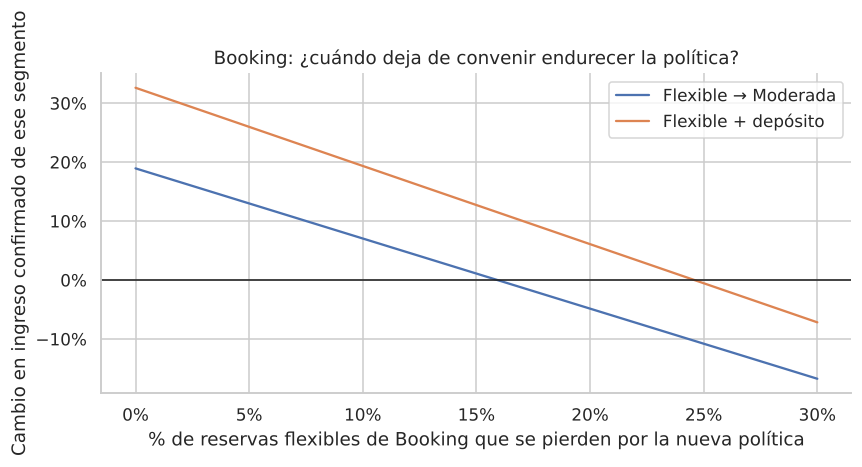

In [26]:
# Si una fracción g de las reservas afectadas se pierde por endurecer la política, ¿el ingreso confirmado aún mejora?
# Ingreso confirmado por reserva afectada: hoy ∝ (1 − p_act); con política y sin pérdida de demanda ∝ (1 − p_new)
# Punto de equilibrio: (1 − g) · (1 − p_new) = (1 − p_act)  →  g* = 1 − (1 − p_act)/(1 − p_new)
esc["Caída máxima de volumen tolerable"] = 1 - (1 - esc.p_act) / (1 - esc.p_new)

display(esc[["Canal", "Escenario", "Caída máxima de volumen tolerable"]]
        .style.format({"Caída máxima de volumen tolerable": "{:.1%}"}))

g = np.linspace(0, .30, 31)
fig, ax = plt.subplots(figsize=(8, 4))
for _, r in esc[esc.Canal == "Booking"].iterrows():
    ax.plot(g, (1 - g) * (1 - r.p_new) / (1 - r.p_act) - 1, label=r.Escenario)
ax.axhline(0, color="k", lw=1); pct(ax); pct(ax, "x")
ax.set_xlabel("% de reservas flexibles de Booking que se pierden por la nueva política")
ax.set_ylabel("Cambio en ingreso confirmado de ese segmento"); ax.set_title("Booking: ¿cuándo deja de convenir endurecer la política?"); ax.legend()
plt.tight_layout(); plt.show()

**Lectura.** Esta sensibilidad ayuda a definir el **KR2 del OKR (el campo «[__] %»)**: la caída de volumen máxima aceptable en el piloto es la que haga cero el beneficio (punto de corte de las curvas): ≈ 15,9 % si en Booking se pasa a Moderada y ≈ 24,6 % si se exige depósito. Fijar el tope por debajo de ese umbral con margen de seguridad protege al hotel de perder más ingreso del que recupera. Los datos históricos **no permiten medir** la elasticidad real de la demanda: es lo que debe medir el piloto.

## 8. Conclusiones

### 8.1 Qué muestran los datos y cómo sostienen las tres preguntas

| Pregunta | Evidencia del EDA | Conclusión |
|---|---|---|
| **P1 · Reservas adicionales** | ≈ 19,0 % de las reservas se cancela; las cancelaciones **por noche** son estables (≈ 21,0 ± 4,7), crecen con el volumen en cartera y una regla simple (error 3,24) supera al promedio fijo (3,62) | Las cancelaciones **son anticipables** con margen de error acotado → aceptar reservas adicionales es viable |
| **P2 · Pago anticipado focalizado** | Con depósito se cancela 9,9 % vs. 27,1 % sin él; **dentro de Flexible/Moderada, 14,8 % vs. 27,5 %**; el riesgo se concentra en anticipación larga, política Flexible e historial de cancelaciones; un modelo base discrimina bien (AUC 0,770) | El riesgo es **heterogéneo y predecible** → focalizar el depósito rinde más que aplicarlo a todos |
| **P3 · Políticas por canal** | Booking (26,9 %) y Airbnb (22,3 %) cancelan más; Booking pesa 47 % del ingreso perdido; la mezcla de políticas es igual entre canales | La diferencia es **del canal**, y Flexible → Moderada / depósito tiene margen de reducción importante |

**Hilo narrativo para los siguientes entregables:** *cancelan ~1 de cada 5 reservas → se puede anticipar cuántas (P1) → y cuáles (P2) → y el foco está en Booking/Airbnb con política flexible (P3).*

### 8.2 Limitaciones y cuidados al interpretar
- **Calidad:** 300 duplicados eliminados; ~4 % sin canal o país (categoría «No registrado»).
- **Sin fecha de cancelación:** los datos dicen *si* se canceló, no *cuándo*. Se asume que la cancelación se conoce antes de la llegada; si ocurriera el mismo día, el colchón de reservas adicionales sería riesgoso.
- **Periodo atípico (promociones de 2023):** no hay huella visible en tarifa, política ni canal; conviene probar la robustez de los modelos excluyendo o ponderando 2023.
- **Censura temporal:** rampa de arranque (ene–abr 2023) y cola (después del 18-jun-2025) distorsionan las series; por eso series y modelo usan la ventana 1-may-2023 → 18-jun-2025 y las cifras históricas la base completa.
- **Escala vs. capacidad:** la ocupación por noche equivale a ≈ 8,1 veces las 38 habitaciones; los resultados se leen en términos **relativos** y la fase técnica debe fijar un supuesto de capacidad.
- **Asociación ≠ causalidad:** quien paga depósito o elige tarifa rígida puede ser un huésped distinto. Los ahorros son estimaciones que el piloto debe validar.
- **Fuga de información:** `ingreso_total` queda fuera de cualquier modelo.

### 8.3 Próximos pasos (fase de desarrollo técnico)
1. Modelo de cancelación (con validación temporal) y calibración de probabilidades.
2. P1: pronóstico de cancelaciones por noche, percentil 10 como regla de reservas adicionales y simulación de incidencias con el supuesto de capacidad acordado.
3. P2: umbral de alto riesgo (p > 30 %) y cálculo del ingreso protegido, **incluyendo la política** para no sobreestimar el efecto del depósito.
4. P3: simulación de políticas por canal y definición del tope de caída de volumen para el KR2.

## 9. Cifras clave del EDA (fuente única)

Este bloque guarda en `cifras_eda.json` todas las cifras citadas en el texto. El informe en PDF y el documento se generan desde este mismo archivo, así que **todos los entregables muestran los mismos números**.

In [27]:
def pc(x, d=1): return f"{x*100:.{d}f} %".replace(".", ",")
def mi(x): return f"{x:,.0f}".replace(",", ".")
def d1(x, d=1): return f"{x:.{d}f}".replace(".", ",")

C = {}
# --- calidad y limpieza
C["n_raw"] = mi(len(raw)); C["n_dup"] = mi(n_dup); C["n_unicas"] = mi(len(df)); C["n_ventana"] = mi(len(dv))
C["pct_nulo_canal"] = pc(raw.canal.isna().mean()); C["pct_nulo_pais"] = pc(raw.pais_origen.isna().mean())
for c, k in [("tarifa_noche", "out_tarifa"), ("noches", "out_noches"), ("anticipacion_dias", "out_antic")]:
    q1, q3 = raw[c].quantile([.25, .75]); i = q3 - q1
    C[k] = pc(((raw[c] > q3 + 1.5*i) | (raw[c] < q1 - 1.5*i)).mean())
C["tasa_canal_nr"] = pc(df.loc[df.canal == "No registrado", "cancelada"].mean())
rpd = unicas.groupby("fecha_llegada").size()
C["res_dia_ene23"] = d1(rpd["2023-01"].mean(), 0); C["res_dia_normal"] = d1(rpd["2023-06":"2025-05"].mean(), 0)
C["tasa_t1_23"] = pc(unicas[unicas.fecha_llegada < "2023-04-01"].cancelada.mean())
C["antic_cola"] = d1(cola.anticipacion_dias.mean(), 0); C["tasa_cola"] = pc(cola.cancelada.mean())
# --- panorama
C["tasa_global"] = pc(tasa_global); C["perdido_M"] = millones(perdido); C["potencial_M"] = millones(potencial)
ay = dv.groupby("anio_llegada").cancelada.mean(); C["tasa23"], C["tasa24"], C["tasa25"] = [pc(v) for v in ay.values]
C["share_vol_booking"] = pc((df.canal == "Booking").mean()); C["pct_flex"] = pc((df.politica_cancelacion == "Flexible").mean())
C["pct_dep"] = pc(df.deposito_pagado.mean())
tm = a23.tarifa_media.values; tb = a23.pct_tarifa_baja.values
C["tar23"], C["tar24"], C["tar25"] = [f"${mi(v)}" for v in tm]; C["tb23"], C["tb24"], C["tb25"] = [pc(v) for v in tb]
C["tasa_alta"] = pc(ta.loc["Temporada alta", "tasa"]); C["tasa_baja"] = pc(ta.loc["Temporada baja", "tasa"])
C["dif_tarifa_alta"] = pc(ta.loc["Temporada alta", "tarifa"] / ta.loc["Temporada baja", "tarifa"] - 1, 0)
# --- P1
C["canc_dia_media"] = d1(diario.cancelaciones.mean(), 1); C["canc_dia_std"] = d1(diario.cancelaciones.std())
C["cv_dia"] = pc(diario.cancelaciones.std() / diario.cancelaciones.mean(), 0); C["res_dia_media"] = d1(diario.reservas.mean(), 0)
C["r_dia"] = d1(r_dia, 2); C["mae_fijo"] = d1(mae_fijo, 2); C["mae_tasa"] = d1(mae_tasa, 2); C["piso_ruido"] = d1(piso_ruido, 1)
C["n_noches_prueba"] = str(len(te)); C["p10_dia"] = d1(p10, 0)
C["conf_noche_media"] = d1(nd.confirmadas.mean(), 0); C["conf_noche_max"] = d1(nd.confirmadas.max(), 0); C["ratio_cap"] = d1(nd.confirmadas.mean() / HABITACIONES)
# --- P2
C["tasa_sin"] = pc(t_dep.loc["Sin pago anticipado", "mean"]); C["tasa_con"] = pc(t_dep.loc["Con pago anticipado", "mean"])
C["ratio_global"] = d1(t_dep.loc["Sin pago anticipado", "mean"] / t_dep.loc["Con pago anticipado", "mean"])
C["fm_sin"] = pc(tfm.loc[0, "mean"]); C["fm_con"] = pc(tfm.loc[1, "mean"]); C["ratio_fm"] = d1(tfm.loc[0, "mean"] / tfm.loc[1, "mean"])
nr = df[df.politica_cancelacion == "No reembolsable"]
C["nr_dep_pct"] = pc(nr.deposito_pagado.mean(), 0); C["nr_tasa"] = pc(nr.cancelada.mean())
C["dep_fm_pct"] = pc(fm.deposito_pagado.mean(), 0)
for k, p in [("pol_flex", "Flexible"), ("pol_mod", "Moderada"), ("pol_nr", "No reembolsable")]:
    C[k] = pc(df.loc[df.politica_cancelacion == p, "cancelada"].mean())
ra = df.groupby("rango_anticipacion", observed=True).cancelada.mean(); C["a_0_7"] = pc(ra.iloc[0]); C["a_181"] = pc(ra.iloc[-1])
cp = df.groupby("cancelaciones_previas").cancelada.mean(); C["prev0"] = pc(cp.loc[0]); C["prev2"] = pc(cp.loc[2]); C["prev3"] = pc(cp.loc[3])
qt = df.groupby("quintil_tarifa", observed=True).cancelada.mean(); C["q_min"] = pc(qt.min()); C["q_max"] = pc(qt.max())
C["auc_gbm"] = d1(auc_gbm, 3); C["auc_lr"] = d1(auc_lr, 3)
C["n_sin_test"] = mi(len(te_sin)); C["n_alto"] = mi(len(alto)); C["pct_alto"] = pc(len(alto) / len(te_sin), 0)
C["tasa_alto"] = pc(alto.cancelada.mean()); C["tasa_resto"] = pc(te_sin[te_sin.p <= .30].cancelada.mean())
C["perd_alto_M"] = millones(alto.ingreso_perdido.sum()); C["pct_perd_alto"] = pc(alto.ingreso_perdido.sum() / te_sin.ingreso_perdido.sum(), 0)
# --- P3
for c, k in [("Booking", "booking"), ("Airbnb", "airbnb"), ("Directo web", "web"), ("Agencia", "agencia"), ("Telefono", "tel")]:
    C[f"tasa_{k}"] = pc(canal.loc[c, "tasa"])
C["share_perd_booking"] = pc(canal.loc["Booking", "share_perdido"], 0); C["share_perd_airbnb"] = pc(canal.loc["Airbnb", "share_perdido"], 0)
C["bk_p_act"] = pc(cel[("Booking", "Flexible", 0)]); C["bk_p_mod"] = pc(cel[("Booking", "Moderada", 0)]); C["bk_p_dep"] = pc(cel[("Booking", "Flexible", 1)])
e = esc.set_index(["Canal", "Escenario"])
for c, k in [("Booking", "bk"), ("Airbnb", "ab")]:
    C[f"{k}_hoy"] = pc(e.loc[(c, "Flexible → Moderada"), "Tasa del canal hoy"])
    C[f"{k}_mod"] = pc(e.loc[(c, "Flexible → Moderada"), "Tasa del canal con la política"])
    C[f"{k}_dep"] = pc(e.loc[(c, "Flexible + depósito"), "Tasa del canal con la política"])
    C[f"n_afect_{k}"] = mi(e.loc[(c, "Flexible → Moderada"), "Reservas afectadas"])
    C[f"be_{k}_mod"] = pc(e.loc[(c, "Flexible → Moderada"), "Caída máxima de volumen tolerable"])
    C[f"be_{k}_dep"] = pc(e.loc[(c, "Flexible + depósito"), "Caída máxima de volumen tolerable"])
    C[f"rec_{k}_mod"] = millones(e.loc[(c, "Flexible → Moderada"), "Ingreso recuperable"]); C[f"rec_{k}_dep"] = millones(e.loc[(c, "Flexible + depósito"), "Ingreso recuperable"])

json.dump(C, open("../../datos/cifras_eda.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print(f"{len(C)} cifras guardadas en cifras_eda.json")
pd.Series(C).to_frame("valor").head(15)

100 cifras guardadas en cifras_eda.json


,valor
n_raw,100.300
n_dup,300
n_unicas,100.000
n_ventana,86.168
pct_nulo_canal,"4,0 %"
pct_nulo_pais,"3,9 %"
out_tarifa,"1,5 %"
out_noches,"1,2 %"
out_antic,"3,6 %"
tasa_canal_nr,"19,4 %"
